In [1]:
%load_ext autoreload
%autoreload 2

import MonteCarloPricing
import numpy as np
import matplotlib.pyplot as plt 
import scipy.stats as st

To Do
- Write a method for the MC convergence where you compare analytical BS to MC 
- Millstein

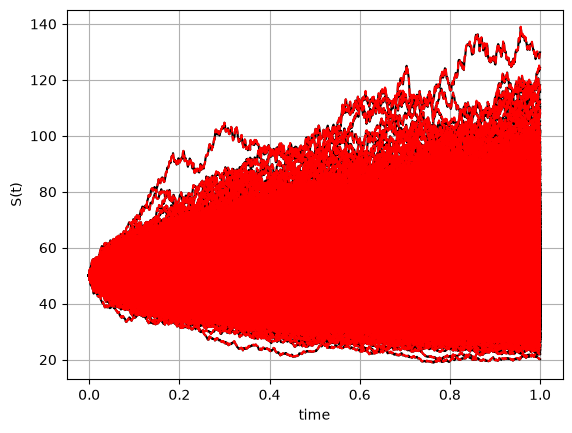

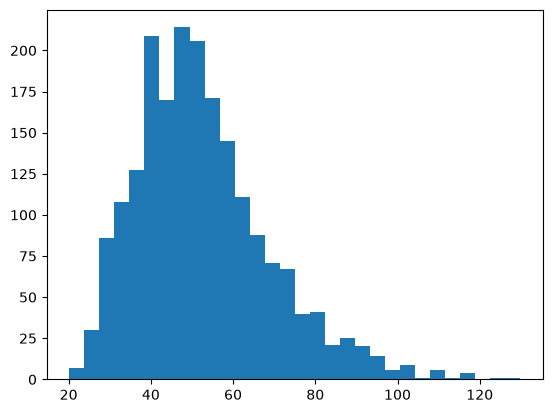

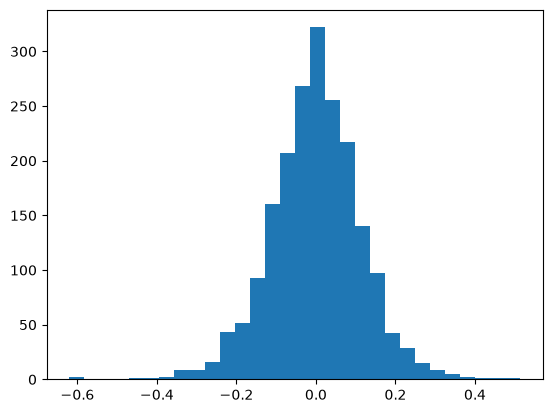

E(S(T)) = 5.262910e+01, Var(S(T))=264.553461, Std(S(T))=16.265099


In [30]:
paths_no = 2000
step_no = 1000

end_time=1
interest_rate = 0.05

vol = 0.3
S_0 = 50

paths = MonteCarloPricing.generate_GBM_paths_euler(paths_no, step_no, end_time, interest_rate, vol, S_0)

time = paths["time"]
S_euler_approx = paths["S_euler_approx"]
S_exact = paths["S_exact"]

plt.figure(1)
plt.plot(time, np.transpose(S_euler_approx),'k')
plt.plot(time, np.transpose(S_exact),'--r')
plt.grid()
plt.xlabel("time")
plt.ylabel("S(t)")

plt.show()

plt.hist(S_euler_approx[:,-1], 30)
plt.show()


plt.hist(S_euler_approx[:,-1]-S_exact[:,-1], 30)
plt.show()

mean_last_price = np.mean(S_euler_approx[:,-1])
var_last_price = np.var(S_euler_approx[:,-1])
print("E(S(T)) = {0:4e}, Var(S(T))={1:4f}, Std(S(T))={2:4f}".format(mean_last_price,var_last_price,np.sqrt(var_last_price)))


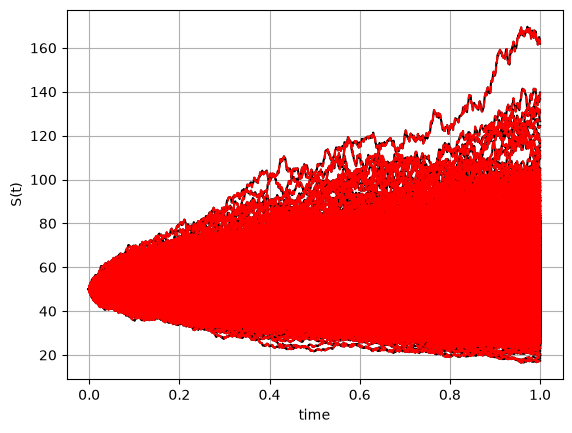

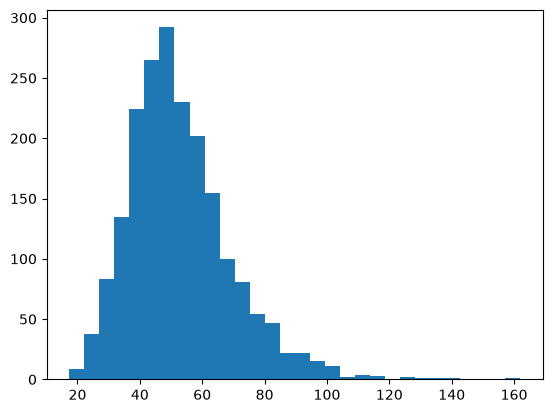

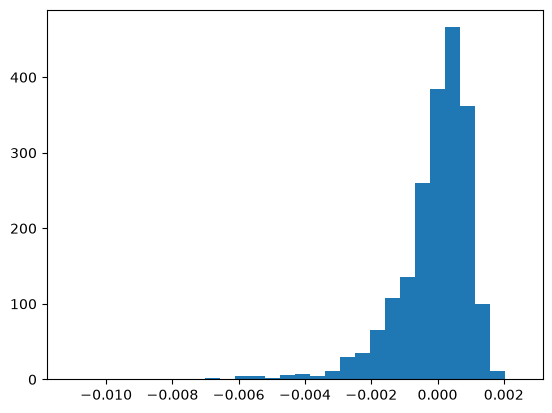

E(S(T)) = 5.285911e+01, Var(S(T))=268.792437, Std(S(T))=16.394891


In [31]:
paths_no = 2000
step_no = 1000

end_time=1
interest_rate = 0.05

vol = 0.3
S_0 = 50

paths = MonteCarloPricing.generate_GBM_paths_milstein(paths_no, step_no, end_time, interest_rate, vol, S_0)

time = paths["time"]
S_milstein_approx = paths["S_milstein_approx"]
S_exact = paths["S_exact"]

plt.figure(1)
plt.plot(time, np.transpose(S_milstein_approx),'k')
plt.plot(time, np.transpose(S_exact),'--r')
plt.grid()
plt.xlabel("time")
plt.ylabel("S(t)")

plt.show()

plt.hist(S_milstein_approx[:,-1], 30)
plt.show()

plt.hist(S_milstein_approx[:,-1]-S_exact[:,-1], 30)
plt.show()

mean_last_price = np.mean(S_milstein_approx[:,-1])
var_last_price = np.var(S_milstein_approx[:,-1])
print("E(S(T)) = {0:4e}, Var(S(T))={1:4f}, Std(S(T))={2:4f}".format(mean_last_price,var_last_price,np.sqrt(var_last_price)))


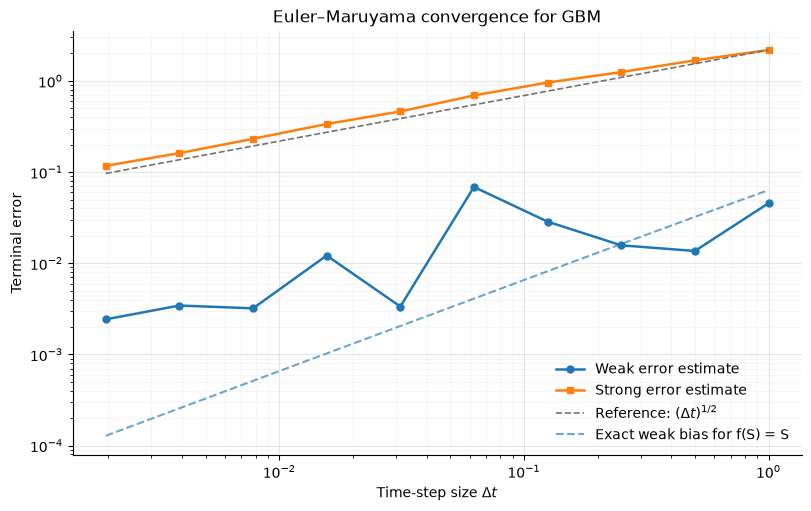

In [25]:
step_counts = 2 ** np.arange(10)  # 1, 2, 4, ..., 512

errors = MonteCarloPricing.weak_and_strong_convergence(
    paths_no, step_counts, end_time, interest_rate, vol, S_0
)

# Sort into increasing time-step size.
order = np.argsort(errors["dt"])
dt = errors["dt"][order]
weak = errors["error_weak"][order]
strong = errors["error_strong"][order]

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

ax.loglog(
    dt, weak, "o-",
    color="tab:blue", linewidth=1.8, markersize=5,
    label="Weak error estimate",
)
ax.loglog(
    dt, strong, "s-",
    color="tab:orange", linewidth=1.8, markersize=5,
    label="Strong error estimate",
)

# Reference slopes, scaled to the strong error at the largest dt.
ax.loglog(
    dt, strong[-1] * (dt / dt[-1]) ** 0.5,
    "--", color="0.45", linewidth=1.2,
    label=r"Reference: $(\Delta t)^{1/2}$",
)

ax.set(
    title="Euler–Maruyama convergence for GBM",
    xlabel=r"Time-step size $\Delta t$",
    ylabel="Terminal error",
)

ax.grid(which="major", alpha=0.3)
ax.grid(which="minor", alpha=0.1)
ax.spines[["top", "right"]].set_visible(False)

weak_bias = S_0 * np.abs(
(1 + interest_rate * dt) ** (end_time / dt)
- np.exp(interest_rate * end_time)
)

ax.loglog(
dt, weak_bias, "--",
color="tab:blue", alpha=0.65,
label="Exact weak bias for f(S) = S",
)

ax.legend(frameon=False)

plt.show()


In [13]:
# CP = MonteCarloPricing.OptionType.CALL
option_type = "call"
T = 1
r = 0.06
sigma = 0.3
S_0 = 5
K = [S_0]
NoOfSteps =1000

NoOfPathsV = [100,1000,5000,10000] #,50000,100000]

exactPrice = MonteCarloPricing.BS_Call_Option_Price(option_type,S_0,K,sigma,T,r)[0]
print("EUROPEAN OPTION PRICING")
# print(f"Exact option price = {exactPrice:.2f}")

print("N \t S_Euler \t S_Milstein \t Euler_error \t Milstein_error")

for NoOfPathsTemp in NoOfPathsV:
    np.random.seed(1)
    PathsEuler =    MonteCarloPricing.generate_GBM_paths_euler(NoOfPathsTemp,NoOfSteps,T,r,sigma,S_0)
    np.random.seed(1)
    PathsMilstein = MonteCarloPricing.generate_GBM_paths_milstein(NoOfPathsTemp,NoOfSteps,T,r,sigma,S_0)
    S_Euler = PathsEuler["S_euler_approx"]
    S_Milstein = PathsMilstein["S_milstein_approx"]
    priceEuler = MonteCarloPricing.EUOptionPriceFromMCPaths(option_type,S_Euler[:,-1],K,T,r)
    priceMilstein = MonteCarloPricing.EUOptionPriceFromMCPaths(option_type,S_Milstein[:,-1],K,T,r)
    # print("For N = {0} Euler scheme yields option price = {1} and Milstein{2}".format(NoOfPathsTemp,priceEuler,priceMilstein))
    # print("For N = {0} Euler error = {1} and Milstein error {2}".format(NoOfPathsTemp,priceEuler-exactPrice,priceMilstein-exactPrice))
    # print("{0} \t {1:3f} \t {2:3f} \t {1:3f} \t {2:3f}".format(NoOfPathsTemp,priceEuler,priceMilstein, priceEuler-exactPrice,priceMilstein-exactPrice))
    print(f"{NoOfPathsTemp} \t {priceEuler:.3f} \t {priceMilstein:.3f} \t {priceEuler-exactPrice:.3f} \t {priceMilstein-exactPrice:.3f}")
    # print("{0} \t {1} \t {2}".format(NoOfPathsTemp,priceEuler-exactPrice,priceMilstein-exactPrice))

EUROPEAN OPTION PRICING
N 	 S_Euler 	 S_Milstein 	 Euler_error 	 Milstein_error


TypeError: unsupported format string passed to numpy.ndarray.__format__

In [ ]:
print()